In [16]:
import cudaq
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import numpy as np

cudaq.set_target("nvidia")
# cudaq.set_target("nvidia", option='fp64')

In [ ]:
import openfermion
import openfermionpyscf
from openfermion.transforms import jordan_wigner, get_fermion_operator

geometry = [('H', (0.0, 0.0, 0.0)),
            ('H', (0.0, 0.0, 0.30))]
basis = 'sto-3g'
spin = 0
charge = 0
multiplicity = 1

In [18]:
molecule = openfermionpyscf.run_pyscf(openfermion.MolecularData(geometry, basis, multiplicity, charge))

molecule_Hamiltonian = molecule.get_molecular_hamiltonian()
fermion_Hamiltonian = get_fermion_operator(molecule_Hamiltonian)
qubit_Hamiltonian = jordan_wigner(fermion_Hamiltonian)
spin_ham = cudaq.SpinOperator(qubit_Hamiltonian)

/tmp/ipykernel_43632/4150297343.py:6: ComplexWarning: Casting complex values to real discards the imaginary part
  spin_ham = cudaq.SpinOperator(qubit_Hamiltonian)


In [19]:
from openfermion import count_qubits
num_qubits = molecule.n_orbitals * 2
print("Number of qubits:", num_qubits)
num_PauliTerms = len(qubit_Hamiltonian.terms)
print("Number of Pauli Terms: ", num_PauliTerms)
print(qubit_Hamiltonian.terms)
num_electrons = molecule.n_electrons
print("Number of electrons: ", num_electrons)


Number of qubits: 4
Number of Pauli Terms:  15
{(): np.complex128(-0.09057898608834769+0j), ((0, 'Z'),): np.complex128(0.1721839326191555+0j), ((1, 'Z'),): np.complex128(0.17218393261915552+0j), ((2, 'Z'),): np.complex128(-0.22575349222402397+0j), ((3, 'Z'),): np.complex128(-0.22575349222402402+0j), ((0, 'Z'), (1, 'Z')): np.complex128(0.16892753870087907+0j), ((0, 'Y'), (1, 'X'), (2, 'X'), (3, 'Y')): np.complex128(0.04523279994605784+0j), ((0, 'Y'), (1, 'Y'), (2, 'X'), (3, 'X')): np.complex128(-0.04523279994605784+0j), ((0, 'X'), (1, 'X'), (2, 'Y'), (3, 'Y')): np.complex128(-0.04523279994605784+0j), ((0, 'X'), (1, 'Y'), (2, 'Y'), (3, 'X')): np.complex128(0.04523279994605784+0j), ((0, 'Z'), (2, 'Z')): np.complex128(0.12091263261776627+0j), ((0, 'Z'), (3, 'Z')): np.complex128(0.1661454325638241+0j), ((1, 'Z'), (2, 'Z')): np.complex128(0.1661454325638241+0j), ((1, 'Z'), (3, 'Z')): np.complex128(0.12091263261776627+0j), ((2, 'Z'), (3, 'Z')): np.complex128(0.17464343068300453+0j)}
Number of

In [20]:
@cudaq.kernel
def kernel(thetas: list[float]):
    qubits = cudaq.qvector(num_qubits)
    
    for i in range(num_electrons):
        x(qubits[i])
    
    cudaq.kernels.uccsd(qubits, thetas, num_electrons, num_qubits)
    
parameter_count = cudaq.kernels.uccsd_num_parameters(num_electrons, num_qubits)

In [21]:
print("UCCSD parameters: ", parameter_count)

UCCSD parameters:  3


In [22]:
def cost(theta):
    exp_val = cudaq.observe(kernel, spin_ham, theta).expectation()
    
    return exp_val

exp_vals = []

def callback(xk):
    exp_vals.append(cost(xk))
    
np.random.seed(42)
x0 = np.random.normal(0, 1, parameter_count)

UCCSD VQE Energy:  -1.137302300174352
Total number of qubits =  4
Total number of parameters =  3
Total number of terms in the spin hamiltonian =  15
Total elapsed time (s) =  2.409282812001038


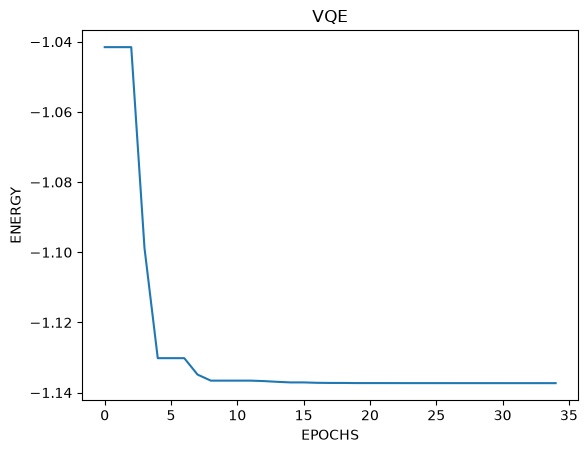

In [29]:
import timeit
import os

os.makedirs("src", exist_ok=True)

exp_vals = []

start_time = timeit.default_timer()
result = minimize(cost, x0, method='COBYLA', callback=callback, options={'maxiter': 50})
end_time = timeit.default_timer()

print("UCCSD VQE Energy: ", result.fun)
print('Total number of qubits = ', num_qubits)
print('Total number of parameters = ', parameter_count)
print('Total number of terms in the spin hamiltonian = ',
      spin_ham.term_count)
print('Total elapsed time (s) = ', end_time - start_time)
plt.plot(exp_vals)
plt.xlabel('EPOCHS')
plt.ylabel('ENERGY')
plt.title('VQE')
plt.savefig("src/h2_pes.png", dpi=200, bbox_inches='tight')
plt.show()

UCCSD VQE Energy:  -1.137302300174352
Total number of qubits =  4
Total number of parameters =  3
Total number of terms in the spin hamiltonian =  15
Total elapsed time (s) =  2.5692237290022604


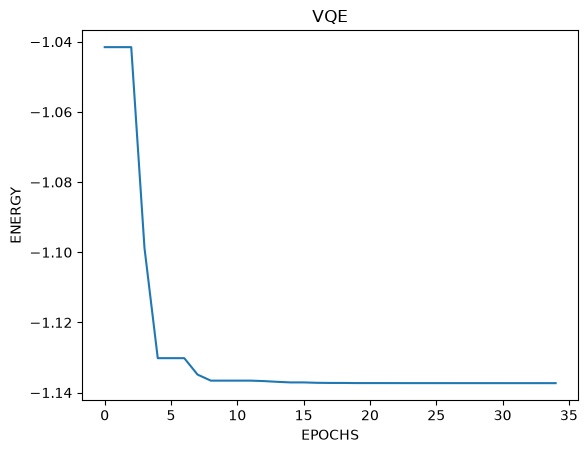

In [24]:
exp_vals = []
start_time = timeit.default_timer()
result = minimize(cost, x0, method='COBYLA', callback=callback, options={'maxiter': 50})
end_time = timeit.default_timer()

print("UCCSD VQE Energy: ", result.fun)
print('Total number of qubits = ', num_qubits)
print('Total number of parameters = ', parameter_count)
print('Total number of terms in the spin hamiltonian = ',
      spin_ham.term_count)
print('Total elapsed time (s) = ', end_time - start_time)

plt.plot(exp_vals)
plt.xlabel('EPOCHS')
plt.ylabel('ENERGY')
plt.title('VQE')
plt.show()